uts graf 

nama: husain fahd salimul aqil
nim: 23031554172

In [1]:
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "uts12345")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung!")

Terhubung!


In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "uts12345")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [3]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    print("Database dikosongkan")

Database dikosongkan


Pertanyaan Pendahuluan (Checkpint)

1. Apa nama database yang digunakan pada tutorial ini?
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!
3. Apa jenis graf pertemanan yang telah dibuat di sini?
jawaban
1. NEO4J
2. Database lain dalam 1 instance bisa diakses dengan mengganti parameter database_ pada driver, atau memakai USE namadb di Cypher. Pembuatan database memakai CREATE DATABASE yang dijalankan di database system.
3. Jenis graf: graf berarah (directed), berupa labeled property graph dengan satu label simpul Person dan relasi KNOWS, tanpa bobot.

In [7]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df["datetime"].min(), df["datetime"].max())
print(len(df))

2015-05-03 03:00:04.384000 2015-09-18 02:59:47.788000
2756101


In [9]:
import os

# Batas akhir memakai "<" pada hari berikutnya agar seluruh hari terakhir ikut masuk
P1_MULAI, P1_SELESAI = "2015-08-15", "2015-08-29"   # 15-28 Agustus
P2_MULAI, P2_SELESAI = "2015-08-29", "2015-09-05"   # 29 Agustus - 4 September

def ambil_periode(df, mulai, selesai):
    m = (df["datetime"] >= mulai) & (df["datetime"] < selesai)
    return df[m].copy()

def ringkas(nama, sub):
    print(f"{nama}")
    print("  baris   :", len(sub))
    print("  visitor :", sub["visitorid"].nunique())
    print("  item    :", sub["itemid"].nunique())
    print("  event   :", sub["event"].value_counts().to_dict())

p1 = ambil_periode(df, P1_MULAI, P1_SELESAI)
p2 = ambil_periode(df, P2_MULAI, P2_SELESAI)

ringkas("P1 (training)", p1)
ringkas("P2 (testing)", p2)

irisan_visitor = set(p1["visitorid"]) & set(p2["visitorid"])
irisan_item = set(p1["itemid"]) & set(p2["itemid"])
print("Visitor di P1 dan P2:", len(irisan_visitor))
print("Item di P1 dan P2   :", len(irisan_item))

# Simpan hasil filter (kolom datetime dibuang agar format sama dengan events.csv asli)
os.makedirs("data_filtered", exist_ok=True)
kolom = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1[kolom].to_csv("data_filtered/events_p1.csv", index=False)
p2[kolom].to_csv("data_filtered/events_p2.csv", index=False)
print("Tersimpan di folder data_filtered/")

P1 (training)
  baris   : 251406
  visitor : 143490
  item    : 73365
  event   : {'view': 242433, 'addtocart': 6738, 'transaction': 2235}
P2 (testing)
  baris   : 121361
  visitor : 71532
  item    : 47023
  event   : {'view': 117219, 'addtocart': 3154, 'transaction': 988}
Visitor di P1 dan P2: 4067
Item di P1 dan P2   : 27931
Tersimpan di folder data_filtered/


In [10]:
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "uts12345")   # ganti dengan password Neo4j Anda

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


In [11]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_unique IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_unique IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

with driver.session() as session:
    create_constraints(session)
print("Constraint siap")

Constraint siap


In [12]:
Q_VIEW = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
"""

Q_CART = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
"""

Q_BUY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
"""

QUERY_PER_EVENT = {"view": Q_VIEW, "addtocart": Q_CART, "transaction": Q_BUY}

def import_batch(tx, event, records):
    tx.run(QUERY_PER_EVENT[event], batch=records)

def impor_csv(path, batch_size=5000):
    total_rows = sum(1 for _ in open(path)) - 1   # kurangi baris header
    total_chunks = (total_rows // batch_size) + 1

    chunks = pd.read_csv(path, chunksize=batch_size)
    with driver.session() as session:
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor"):
            chunk["transactionid"] = (
                chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
            )
            chunk["timestamp"] = chunk["timestamp"].astype("int64")

            for event in QUERY_PER_EVENT:
                sub = chunk[chunk["event"] == event]
                if sub.empty:
                    continue
                records = sub[["timestamp", "visitorid", "itemid", "transactionid"]] \
                              .astype({"visitorid": "int64", "itemid": "int64"}) \
                              .to_dict(orient="records")
                session.execute_write(import_batch, event, records)
    print("Impor selesai:", path)

In [13]:
impor_csv("data_filtered/events_p1.csv", batch_size=5000)

Mengimpor: 100%|██████████| 51/51 [00:41<00:00,  1.22it/s]

Impor selesai: data_filtered/events_p1.csv


In [14]:
with driver.session() as session:
    print("Jumlah simpul per label:")
    for r in session.run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah"):
        print(f"  {r['label']}: {r['jumlah']}")

    print("Jumlah relasi per tipe:")
    for r in session.run("MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah"):
        print(f"  {r['tipe']}: {r['jumlah']}")

Jumlah simpul per label:
  Visitor: 143490
  Item: 73365
Jumlah relasi per tipe:
  VIEWED: 242420
  ADDED_TO_CART: 6696
  BOUGHT: 2235


2.1 Wrangling dan EDA 

In [15]:
# Komposisi simpul
q_simpul = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""

# Komposisi relasi
q_relasi = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session() as session:
    print("Simpul:")
    df_simpul = pd.DataFrame(session.run(q_simpul).data())
    print(df_simpul)

    print("\nRelasi:")
    df_relasi = pd.DataFrame(session.run(q_relasi).data())
    print(df_relasi)

Simpul:
  jenis_simpul  jumlah
0      Visitor  143490
1         Item   73365

Relasi:
    jenis_relasi  jumlah
0         VIEWED  242420
1  ADDED_TO_CART    6696
2         BOUGHT    2235


In [16]:
import numpy as np
from scipy.sparse import csr_matrix

q_matriks = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        ELSE 5 END) AS bobot
"""
with driver.session() as session:
    df_ui = pd.DataFrame(session.run(q_matriks).data())

# Indeks baris (user) dan kolom (item)
u_idx, daftar_user = pd.factorize(df_ui["visitor"])
i_idx, daftar_item = pd.factorize(df_ui["item"])

X = csr_matrix((df_ui["bobot"].values, (u_idx, i_idx)),
               shape=(len(daftar_user), len(daftar_item)))

print("Pasangan visitor-item :", len(df_ui))
print("Shape matriks X (user x item):", X.shape)

Pasangan visitor-item : 200126
Shape matriks X (user x item): (143490, 73365)


In [17]:
def karakter(M, nama_baris, nama_kolom):
    total = M.shape[0] * M.shape[1]
    per_baris = np.diff(M.indptr)          # jumlah entri tak nol per baris
    print(f"Dimensi vektor : {M.shape[1]} ({nama_kolom})")
    print(f"Jumlah vektor  : {M.shape[0]} ({nama_baris})")
    print(f"Shape          : {M.shape}")
    print(f"Entri tak nol  : {M.nnz}")
    print(f"Density        : {M.nnz/total:.6%}")
    print(f"Sparsity       : {1 - M.nnz/total:.6%}")
    print(f"Rata-rata nnz per vektor : {per_baris.mean():.2f}")
    print(f"Median / maks nnz        : {np.median(per_baris):.0f} / {per_baris.max()}")
    print(f"Vektor dengan 1 entri    : {(per_baris == 1).mean():.2%}")

print("=== VSM USER ===")
karakter(X, "user", "item")

=== VSM USER ===
Dimensi vektor : 73365 (item)
Jumlah vektor  : 143490 (user)
Shape          : (143490, 73365)
Entri tak nol  : 200126
Density        : 0.001901%
Sparsity       : 99.998099%
Rata-rata nnz per vektor : 1.39
Median / maks nnz        : 1 / 589
Vektor dengan 1 entri    : 83.09%


In [18]:
XT = X.T.tocsr()

print("=== VSM ITEM ===")
karakter(XT, "item", "user")

=== VSM ITEM ===
Dimensi vektor : 143490 (user)
Jumlah vektor  : 73365 (item)
Shape          : (73365, 143490)
Entri tak nol  : 200126
Density        : 0.001901%
Sparsity       : 99.998099%
Rata-rata nnz per vektor : 2.73
Median / maks nnz        : 1 / 883
Vektor dengan 1 entri    : 56.96%


In [19]:
B = X.copy(); B.data[:] = 1                       # versi biner (ada/tidak ada interaksi)
deg_user = np.asarray(B.sum(axis=1)).ravel()      # jumlah item per user
deg_item = np.asarray(B.sum(axis=0)).ravel()      # jumlah user per item

pasangan_user = (deg_item * (deg_item - 1) / 2).sum()   # pasangan user yang berbagi item
pasangan_item = (deg_user * (deg_user - 1) / 2).sum()   # pasangan item yang dilihat user sama

print(f"Pasangan user-user potensial : {pasangan_user:,.0f}")
print(f"Pasangan item-item potensial : {pasangan_item:,.0f}")
print(f"Item terpopuler dilihat oleh  : {int(deg_item.max())} user")
print(f"User terbanyak berinteraksi dg: {int(deg_user.max())} item")

Pasangan user-user potensial : 1,485,375
Pasangan item-item potensial : 1,217,364
Item terpopuler dilihat oleh  : 883 user
User terbanyak berinteraksi dg: 589 item


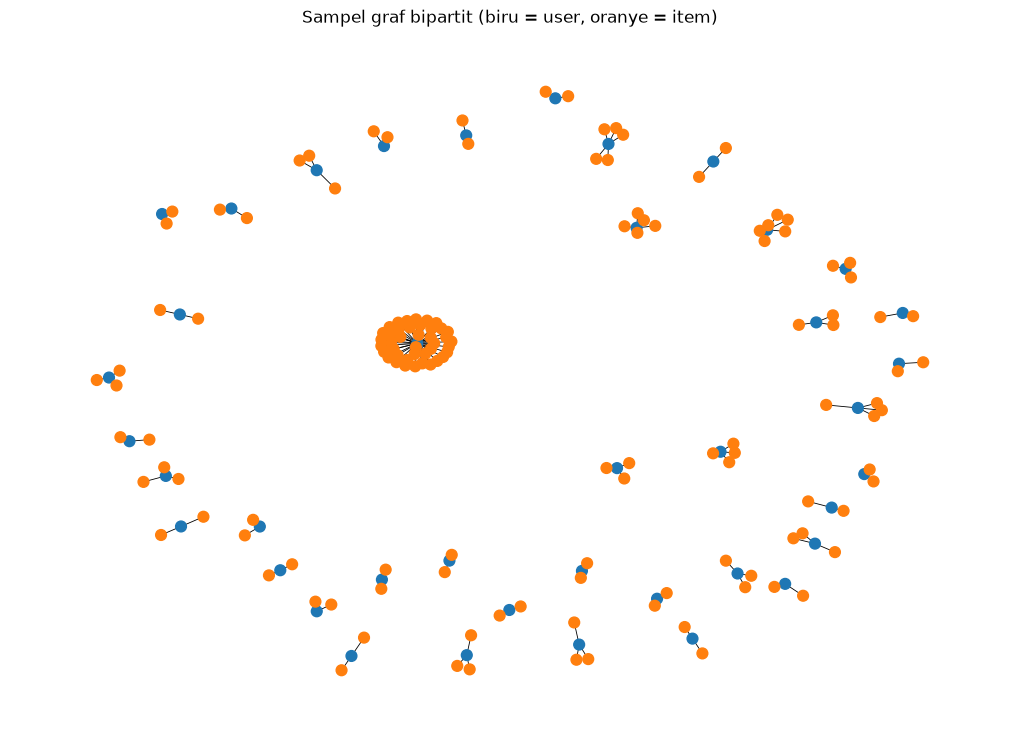

Simpul: 183 | Sisi: 143


In [21]:
import networkx as nx
import matplotlib.pyplot as plt

rng = np.random.default_rng(172)
kandidat = np.where(deg_user >= 2)[0]
sampel_u = rng.choice(kandidat, size=40, replace=False)

sub = df_ui[df_ui["visitor"].isin(daftar_user[sampel_u])]

G = nx.Graph()
for _, r in sub.iterrows():
    G.add_node(f"U{r['visitor']}", tipe="user")
    G.add_node(f"I{r['item']}", tipe="item")
    G.add_edge(f"U{r['visitor']}", f"I{r['item']}", weight=r["bobot"])

warna = ["tab:blue" if G.nodes[n]["tipe"] == "user" else "tab:orange" for n in G]

pos = nx.spring_layout(G, seed=172)   # seed di sini agar tata letak bisa direproduksi
plt.figure(figsize=(10, 7))
nx.draw(G, pos=pos, node_color=warna, node_size=60, width=0.6, with_labels=False)
plt.title("Sampel graf bipartit (biru = user, oranye = item)")
plt.show()
print("Simpul:", G.number_of_nodes(), "| Sisi:", G.number_of_edges())

Sel F: hitung cosine similarity

In [22]:
from scipy.sparse import diags

MIN_USER, TOP_N = 2, 5

aktif = np.where(deg_item >= MIN_USER)[0]       # indeks item dengan >= 2 user
XT_a = XT[aktif]                                 # item aktif x user

norma = np.sqrt(np.asarray(XT_a.multiply(XT_a).sum(axis=1)).ravel())
Xn = diags(1 / norma) @ XT_a                     # normalisasi L2 tiap baris
S = (Xn @ Xn.T).tocsr()                          # cosine = dot product vektor ternormalisasi
S.setdiag(0)
S.eliminate_zeros()
print("Item aktif:", len(aktif), "| pasangan non-nol:", S.nnz)

# Ambil TOP_N tetangga terbaik per item
baris = []
for r in range(S.shape[0]):
    s, e = S.indptr[r], S.indptr[r + 1]
    if s == e:
        continue
    kol, nilai = S.indices[s:e], S.data[s:e]
    pilih = np.argpartition(-nilai, TOP_N)[:TOP_N] if len(nilai) > TOP_N else np.arange(len(nilai))
    for p in pilih:
        baris.append({"a": int(daftar_item[aktif[r]]),
                      "b": int(daftar_item[aktif[kol[p]]]),
                      "skor": float(nilai[p])})
rel = pd.DataFrame(baris)
print("Relasi SIMILAR_TO yang akan ditulis:", len(rel))

# Item acuan: item terpopuler (reproducible, tanpa unsur acak)
ref_item = int(daftar_item[deg_item.argmax()])
print("Item acuan:", ref_item)
print(rel[rel["a"] == ref_item].sort_values("skor", ascending=False))

Item aktif: 31579 | pasangan non-nol: 1629870
Relasi SIMILAR_TO yang akan ditulis: 75854
Item acuan: 187946
         a       b      skor
71  187946  133549  0.064679
72  187946  186820  0.023402
73  187946  435211  0.023140
74  187946  358982  0.023140
75  187946   46399  0.021527


Sel G: kondisi SEBELUM (no. 8)

In [23]:
q_hitung = "MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY jumlah DESC"
with driver.session() as session:
    sebelum = pd.DataFrame(session.run(q_hitung).data())
print(sebelum)

            tipe  jumlah
0         VIEWED  242420
1  ADDED_TO_CART    6696
2         BOUGHT    2235


Sel H: tulis similarity ke graf (no. 7b)

In [24]:
Q_SIM = """
UNWIND $batch AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.skor
"""

def tulis(tx, batch):
    tx.run(Q_SIM, batch=batch)

with driver.session() as session:
    for i in tqdm(range(0, len(rel), 5000), desc="Menulis SIMILAR_TO"):
        session.execute_write(tulis, rel.iloc[i:i + 5000].to_dict(orient="records"))
print("Selesai")

Menulis SIMILAR_TO: 100%|██████████| 16/16 [00:17<00:00,  1.12s/it]

Selesai


Sel I: top 5 similarity (no. 7a) dan kondisi SESUDAH (no. 8)

In [25]:
q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item_mirip, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
with driver.session() as session:
    print(pd.DataFrame(session.run(q_top5, ref=ref_item).data()))
    sesudah = pd.DataFrame(session.run(q_hitung).data())
print(sesudah)

   item_mirip  similarity
0      133549    0.064679
1      186820    0.023402
2      435211    0.023140
3      358982    0.023140
4       46399    0.021527
            tipe  jumlah
0         VIEWED  242420
1     SIMILAR_TO   75854
2  ADDED_TO_CART    6696
3         BOUGHT    2235


Sel J: pilih user acak, KNN k=5

In [28]:
import math

SEED = 172
K = 5

# Item per user di P1 (dasar rekomendasi) dan di P2 (ground truth)
p1 = df_p1.groupby("visitorid")["itemid"].apply(set)
p2 = df_p2.groupby("visitorid")["itemid"].apply(set)

# Kandidat user: ada di P1 dan P2, punya item P1 yang masuk graf similarity,
# dan punya item P2 baru (belum pernah disentuh di P1)
item_punya_sim = set(rel["a"])
kandidat = sorted(
    u for u in p1.index.intersection(p2.index)
    if (p1[u] & item_punya_sim) and (p2[u] - p1[u])
)
print("Jumlah user kandidat:", len(kandidat))

rng_u = np.random.default_rng(SEED)
user_pilih = int(rng_u.choice(kandidat))
seen = p1[user_pilih]
print("User terpilih:", user_pilih, "| item di P1:", len(seen))

# Skor kandidat = jumlah similarity dari tetangga (KNN k=5) item yang pernah disentuh
sub = rel[rel["a"].isin(seen) & ~rel["b"].isin(seen)]
skor = sub.groupby("b")["skor"].sum().sort_values(ascending=False)
rekom = skor.head(K)
print("\nTop-5 kandidat:")
print(rekom)
print("\n3 item yang diiklankan:", list(rekom.index[:3]))

Jumlah user kandidat: 1903
User terpilih: 477077 | item di P1: 1

Top-5 kandidat:
b
414700    0.565685
433904    0.282843
375386    0.043437
Name: skor, dtype: float64

3 item yang diiklankan: [414700, 433904, 375386]


Sel K: Hit@5 dan NDCG@5

In [29]:
truth = p2[user_pilih] - seen
rank = list(rekom.index[:K])

rel_flag = [1 if it in truth else 0 for it in rank]
hit5 = int(any(rel_flag))

dcg = sum(r / math.log2(i + 2) for i, r in enumerate(rel_flag))
idcg = sum(1 / math.log2(i + 2) for i in range(min(len(truth), K)))
ndcg5 = dcg / idcg if idcg > 0 else 0.0

print("Ground truth (P2, item baru):", truth)
print("Rekomendasi top-5          :", rank)
print("Relevan per posisi         :", rel_flag)
print(f"Hit@5  = {hit5}")
print(f"NDCG@5 = {ndcg5:.4f}")

Ground truth (P2, item baru): {301547}
Rekomendasi top-5          : [414700, 433904, 375386]
Relevan per posisi         : [0, 0, 0]
Hit@5  = 0
NDCG@5 = 0.0000


sel j0

In [27]:
import pandas as pd

ev = pd.read_csv("data/events.csv")          # sesuaikan path ke events.csv
ev["waktu"] = pd.to_datetime(ev["timestamp"], unit="ms")

p1_awal, p1_akhir = "2015-08-15", "2015-08-29"   # P1: 15-28 Agustus (batas atas eksklusif)
p2_awal, p2_akhir = "2015-08-29", "2015-09-05"   # P2: 29 Agustus-4 September

df_p1 = ev[(ev["waktu"] >= p1_awal) & (ev["waktu"] < p1_akhir)]
df_p2 = ev[(ev["waktu"] >= p2_awal) & (ev["waktu"] < p2_akhir)]

df_p1.to_csv("events_p1.csv", index=False)
df_p2.to_csv("events_p2.csv", index=False)
print("P1:", len(df_p1), "baris | P2:", len(df_p2), "baris")
print("P1 rentang:", df_p1["waktu"].min(), "->", df_p1["waktu"].max())
print("P2 rentang:", df_p2["waktu"].min(), "->", df_p2["waktu"].max())

P1: 251406 baris | P2: 121361 baris
P1 rentang: 2015-08-15 00:00:07.484000 -> 2015-08-28 23:59:58.153000
P2 rentang: 2015-08-29 00:00:05.252000 -> 2015-09-04 23:59:59.493000


Sel L

In [30]:
from collections import defaultdict

tetangga = defaultdict(list)
for a, b, s in rel[["a", "b", "skor"]].itertuples(index=False):
    tetangga[a].append((b, s))

def rekomendasi(seen_u, k=5):
    skor_u = defaultdict(float)
    for it in seen_u:
        for b, s in tetangga.get(it, []):
            if b not in seen_u:
                skor_u[b] += s
    return [b for b, _ in sorted(skor_u.items(), key=lambda x: -x[1])[:k]]

rng = np.random.default_rng(SEED)
n = min(200, len(kandidat))
sampel = rng.choice(kandidat, size=n, replace=False)

hits, ndcgs = [], []
for u in sampel:
    u = int(u)
    seen_u = p1[u]
    truth_u = p2[u] - seen_u
    rank_u = rekomendasi(seen_u)
    flags = [1 if it in truth_u else 0 for it in rank_u]
    dcg = sum(f / math.log2(i + 2) for i, f in enumerate(flags))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(len(truth_u), K)))
    hits.append(int(any(flags)))
    ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

print(f"User dievaluasi : {n}")
print(f"Hit@5 rata-rata : {np.mean(hits):.4f}")
print(f"NDCG@5 rata-rata: {np.mean(ndcgs):.4f}")

User dievaluasi : 200
Hit@5 rata-rata : 0.0600
NDCG@5 rata-rata: 0.0295


Sel 1: no. 1-2

## 2.1 Wrangling dan EDA

### No. 1-2: Periode waktu dan filter timestamp

Dataset RetailRocket (Mei-September 2015) difilter memakai kolom `timestamp` (unix epoch, milidetik) yang dikonversi ke waktu UTC dengan `pd.to_datetime(..., unit="ms")`. Dua periode yang dipilih:

| Fold | Periode | Fungsi |
|---|---|---|
| P1 (training) | 15-28 Agustus 2015 | Membangun graf, VSM, dan similarity |
| P2 (testing) | 29 Agustus-4 September 2015 | Ground truth evaluasi rekomendasi |

Batas atas tiap periode bersifat eksklusif (`< 29 Agustus 00:00` untuk P1 dan `< 5 September 00:00` untuk P2), sehingga kedua periode berurutan tanpa tumpang tindih. Hasil filter disimpan ke `events_p1.csv` dan `events_p2.csv`.

| | Baris | Rentang waktu aktual |
|---|---|---|
| P1 | 251.406 | 15 Agu 00:00:07 - 28 Agu 23:59:58 |
| P2 | 121.361 | 29 Agu 00:00:05 - 4 Sep 23:59:59 |

Tidak ada kebocoran data:** graf Neo4j dan matriks VSM dibangun hanya dari P1 (251.406 baris interaksi, setara 251.351 relasi di Neo4j). P2 hanya dipakai sebagai ground truth evaluasi pada bagian 2.2.

Sel 2: no. 3

### No. 3: Komposisi subgraph

Komposisi simpul dan relasi diambil lewat Python driver Neo4j dengan dua query Cypher.

```cypher
MATCH (n) RETURN labels(n)[0] AS tipe, count(*) AS jumlah
```
- `MATCH (n)` mencocokkan semua simpul.
- `labels(n)[0]` mengambil label simpul (`Visitor` atau `Item`).
- `count(*)` menghitung jumlah simpul. Cypher otomatis mengelompokkan hasil per kolom non-agregat (`tipe`), jadi hasilnya jumlah per jenis simpul.

```cypher
MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY jumlah DESC
```
- `MATCH ()-[r]->()` mencocokkan semua relasi berarah tanpa memperhatikan jenis simpul ujungnya.
- `type(r)` mengambil jenis relasi, `count(*)` menghitungnya, dan `ORDER BY ... DESC` mengurutkan dari yang terbanyak.

Hasil:

| Jenis | Jumlah |
|---|---|
| Simpul Visitor (user) | 143.490 |
| Simpul Item | 73.365 |
| Relasi VIEWED | 242.420 |
| Relasi ADDED_TO_CART | 6.696 |
| Relasi BOUGHT | 2.235 |
| Total relasi | 251.351 |

Uraian:graf ini bipartit dengan dua jenis simpul, `Visitor` (user) dan `Item`. Relasi hanya menghubungkan Visitor ke Item, tidak pernah Visitor ke Visitor atau Item ke Item. Karena itu proyeksi user-user dan item-item diperlukan jika ingin membandingkan sesama user atau sesama item.

Interaksi didominasi `VIEWED` (sekitar 96% dari seluruh relasi). Jumlah relasi (251.351) lebih besar daripada jumlah pasangan visitor-item yang unik (200.126) karena satu pasangan bisa punya beberapa event, misalnya melihat lalu memasukkan ke keranjang.

Sel 3: no. 4

### No. 4: VSM pada simpul User

Setiap user direpresentasikan sebagai vektor biner di ruang item: nilai 1 jika user berinteraksi dengan item tersebut, 0 jika tidak. Semua vektor disusun menjadi matriks X (user × item) dalam format sparse (CSR).

| Karakteristik | Nilai |
|---|---|
| Dimensi vektor | 73.365 (item) |
| Jumlah vektor | 143.490 (user) |
| Shape matriks X | (143.490, 73.365) |
| Entri tak nol | 200.126 |
| Density / Sparsity | 0,001901% / 99,998099% |
| Rata-rata nnz per vektor | 1,39 |
| Median / maks nnz | 1 / 589 |
| Vektor dengan 1 entri | 83,09% |

Plot networkx (sampel 183 simpul, 143 sisi): sebagian besar user (biru) hanya terhubung ke 1-3 item (oranye) dan membentuk gugus-gugus kecil yang terpisah. Satu user di tengah terhubung ke banyak item. Ini selaras dengan statistik: maksimum 589 item per user, sedangkan median hanya 1.

Cara membaca:pada VSM user, dua user mirip jika punya banyak item yang sama.

Mengapa sparsity setinggi ini:** rata-rata user hanya berinteraksi dengan 1,39 dari 73.365 item, sehingga hampir semua entri bernilai 0. Matriks harus disimpan dalam format sparse. Format padat akan menyimpan sekitar 10,5 miliar sel padahal yang terisi hanya 200.126.

Implikasi:** pada vektor satu entri, cosine similarity tidak informatif. Dua user yang masing-masing hanya punya satu item yang sama selalu bernilai 1,0, dan itu terjadi pada 83% user.

Sel 4: no. 5

### No. 5: VSM pada simpul Item

Setiap item direpresentasikan sebagai vektor biner di ruang user. Ini adalah transpos dari matriks sebelumnya (X^T).

| Karakteristik | Nilai |
|---|---|
| Dimensi vektor | 143.490 (user) |
| Jumlah vektor | 73.365 (item) |
| Shape matriks X^T | (73.365, 143.490) |
| Entri tak nol | 200.126 |
| Density / Sparsity | 0,001901% / 99,998099% |
| Rata-rata nnz per vektor | 2,73 |
| Median / maks nnz | 1 / 883 |
| Vektor dengan 1 entri | 56,96% |

Cara membaca:pada VSM item, dua item mirip jika dilihat oleh banyak user yang sama.

**Uraian:** entri tak nol dan sparsity sama dengan VSM user karena matriksnya sama, hanya ditranspos. Bedanya, vektor item lebih padat (rata-rata 2,73 interaksi per item) dan hanya 56,96% yang berentri tunggal. Item terpopuler dilihat oleh 883 user. Plot networkx sampel yang sama (bipartit, 183 simpul, 143 sisi) berlaku untuk kedua VSM karena keduanya berasal dari graf bipartit yang sama, hanya sudut pandangnya berbeda.

Sel 5: no. 6

### No. 6: Proyeksi mana yang lebih baik?

| Aspek | User-user | Item-item |
|---|---|---|
| Jumlah simpul | 143.490 | 73.365 |
| Pasangan potensial (batas atas) | 1.485.375 | 1.217.364 |
| Simpul dengan 1 interaksi | 83,09% | 56,96% |
| Simpul dengan ≥2 interaksi | sekitar 24.265 | 31.579 |
| Dominasi satu hub | 1 item (883 user) menyumbang 389.403 pasangan, sekitar 26% | 1 user (589 item) menyumbang 173.166 pasangan, sekitar 14% |

Jumlah pasangan potensial adalah batas atas, karena pasangan yang berbagi lebih dari satu item atau user dihitung berkali-kali.

Mengapa jumlah simpul dan pasangan menentukan efisiensi:proyeksi menghubungkan dua simpul yang berbagi tetangga. Satu hub dengan n tetangga menghasilkan sekitar n(n-1)/2 pasangan. Pada proyeksi user-user, item terpopuler (883 user) saja menghasilkan sekitar 389 ribu pasangan, sehingga satu simpul mendominasi hasil dan membuat banyak pasangan yang kurang bermakna.

Mengapa vektor satu entri bermasalah:** dua vektor yang masing-masing hanya punya satu entri pada dimensi yang sama selalu bernilai cosine 1,0, apa pun kontennya. Proporsi vektor seperti ini lebih besar pada user (83,09%) daripada item (56,96%), sehingga similarity item lebih informatif.

Kesimpulan: proyeksi item-item lebih baik.
-Efisien:jumlah simpul hanya sekitar setengah dari proyeksi user-user dan jumlah pasangannya lebih sedikit, sehingga komputasi dan penyimpanan lebih ringan.
-Efektif:vektor item lebih padat, lebih banyak simpul yang punya cukup interaksi untuk dibandingkan, dan pengaruh satu hub lebih kecil.
- Ini sejalan dengan praktik umum rekomendasi e-commerce (item-based collaborative filtering), karena item relatif stabil dan lebih banyak punya riwayat interaksi daripada user.

Sel 6: no. 7 dan 7a

### No. 7: Similarity pada proyeksi item-item

Metode:cosine similarity antar vektor item dengan Python (scipy sparse).

Rumus:untuk dua vektor item a dan b, cos(a, b) = (a · b) / (‖a‖ ‖b‖). Karena vektor bernilai biner, pembilangnya adalah jumlah user yang berinteraksi dengan kedua item. Penyebutnya adalah akar jumlah user item a dikali akar jumlah user item b.

Contoh:item A dilihat 4 user, item B dilihat 9 user, dan 2 user melihat keduanya. Maka cos = 2 / (√4 × √9) = 2/6 ≈ 0,33.

Implementasi: vektor dinormalisasi L2 terlebih dahulu, sehingga similarity semua pasangan dapat dihitung sekaligus lewat satu perkalian matriks sparse `Xn @ Xn.T`. Cara ini efisien karena tidak menyimpan angka nol.

Keputusan desain:
1. Similarity hanya dihitung untuk item dengan **minimal 2 user (`MIN_USER = 2`). Tanpa filter ini, ratusan item yang hanya dilihat oleh satu user yang sama akan semuanya bernilai 1,0. Item aktif: 31.579 dari 73.365 (sekitar 43%).
2. Ke graf hanya ditulis 5 tetangga teratas per item** (`TOP_N = 5`), bukan semua pasangan, agar penulisan ke Neo4j ringan.

Hasil:pasangan non-nol 1.629.870 (berarah, A→B dan B→A dihitung dua kali, sehingga pasangan unik 814.935). Relasi `SIMILAR_TO` yang ditulis: 75.854.

Item acuan: 187946, yaitu item terpopuler (dilihat 883 user), dipilih tanpa unsur acak agar reproducible.

### No. 7a: Query 5 similarity tertinggi

```cypher
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item_mirip, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
```
- `MATCH` mencari item acuan dan relasi `SIMILAR_TO` keluarnya ke item lain.
- `RETURN` menampilkan item tetangga dan skornya.
- `ORDER BY ... DESC LIMIT 5` mengurutkan dari skor tertinggi dan mengambil 5 teratas.

| item_mirip | similarity |
|---|---|
| 133549 | 0,064679 |
| 186820 | 0,023402 |
| 435211 | 0,023140 |
| 358982 | 0,023140 |
| 46399 | 0,021527 |

Skor tertinggi hanya 0,065 karena item acuan adalah item terpopuler. Norma vektornya besar (883 user), sedangkan tetangganya hanya beririsan dengan sebagian kecil user tersebut, sehingga cosine teredam. Ini bukan kesalahan hitung.

Sel 7: no. 7b

### No. 7b: Menulis similarity kembali ke graf

Skor ditulis sebagai relasi `SIMILAR_TO` dengan properti `score`, dalam batch 5.000 baris:

```cypher
UNWIND $batch AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.skor
```
- `UNWIND $batch` memecah daftar baris menjadi satu baris per iterasi.
- `MATCH` menemukan dua simpul item yang sudah ada.
- `MERGE` membuat relasi `SIMILAR_TO` hanya jika belum ada, sehingga tidak terduplikasi.
- `SET s.score` menyimpan nilai similarity sebagai properti relasi.

Hasil query untuk item acuan ditampilkan pada screenshot berikut (item 187946 di tengah, dengan 5 relasi `SIMILAR_TO` ke tetangganya):

![Graf SIMILAR_TO item 187946](visualisation.png)

Sel 8: no. 8

### No. 8: Kondisi sebelum dan sesudah perhitungan similarity

Query yang dipakai (dijalankan sebelum Sel H dan sesudah Sel H):

```cypher
MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY jumlah DESC
```

| Jenis relasi | Sebelum | Sesudah |
|---|---|---|
| VIEWED | 242.420 | 242.420 |
| ADDED_TO_CART | 6.696 | 6.696 |
| BOUGHT | 2.235 | 2.235 |
| SIMILAR_TO | tidak ada | **75.854** |

Sebelum perhitungan, graf hanya berisi relasi interaksi dan belum ada `SIMILAR_TO`. Sesudahnya ada 75.854 relasi `SIMILAR_TO` baru, sama persis dengan jumlah baris `rel` yang dihitung di Python, artinya semua relasi masuk tanpa duplikat. Relasi lain tidak berubah.

Untuk visualisasi graf, query berikut menampilkan item acuan beserta tetangganya (lihat screenshot pada no. 7b):

```cypher
MATCH p=(a:Item {itemId: 187946})-[:SIMILAR_TO]->() RETURN p
```
Pada kondisi sebelum, query ini tidak mengembalikan record karena relasi `SIMILAR_TO` belum ada. Setelah Sel H, hasilnya graf dengan item 187946 di tengah dan 5 tetangga.

Sel 9: seluruh 2.2

## 2.2 Analytics

### Pendekatan

Rekomendasi bersifat item-based collaborative filtering dengan KNN k = 5. Setiap item punya 5 tetangga terdekat berdasarkan cosine similarity (relasi `SIMILAR_TO`). Skor kandidat untuk seorang user adalah jumlah similarity dari tetangga semua item yang pernah ia sentuh di P1, lalu item yang sudah pernah disentuh dikeluarkan. Ground truth adalah item yang disentuh user di P2 dan belum pernah disentuh di P1.

KNN (k = 5): pada setiap item hanya 5 tetangga dengan cosine tertinggi yang disimpan. Item yang mirip dengan beberapa item riwayat user mendapat skor lebih besar karena skornya dijumlahkan, lalu kandidat diurutkan dari skor tertinggi.

### No. 1a: Pemilihan user acak (reproducible)

User dipilih dengan `np.random.default_rng(172)` dari **1.903 user kandidat**, yaitu user yang ada di P1 dan P2, punya item P1 yang masuk graf similarity, dan punya minimal satu item baru di P2. Seed tetap membuat hasil sama di setiap eksekusi.

User terpilih: **477077** (1 item di P1).

### No. 1b: 3 item yang diiklankan (k = 5)

| Peringkat | Item | Skor |
|---|---|---|
| 1 | 414700 | 0,5657 |
| 2 | 433904 | 0,2828 |
| 3 | 375386 | 0,0434 |

Item tunggal user ini hanya punya 3 tetangga di graf similarity, sehingga daftar top-5 hanya berisi 3 item. Ketiganya diiklankan.

### No. 2: Evaluasi

Hit@5:bernilai 1 jika minimal satu item di top-5 ada di ground truth, selain itu 0. Metrik ini hanya melihat ada atau tidaknya item relevan, bukan posisinya.

NDCG@5: menghargai posisi item relevan. Relevansi bersifat biner, dan DCG = Σ rel_i / log2(i + 1). Item relevan di peringkat 1 mendapat bobot 1, di peringkat 2 bobotnya 1/log2(3) ≈ 0,63, dan seterusnya. DCG dibagi IDCG (urutan terbaik yang mungkin) sehingga nilainya berada di rentang 0 sampai 1.

Contoh:jika satu-satunya item relevan berada di peringkat 2, maka Hit@5 = 1 dan NDCG@5 ≈ 0,63. Jika di peringkat 1, maka Hit@5 = 1 dan NDCG@5 = 1.

Evaluasi user tunggal (477077):** ground truth P2 = {301547}, tidak ada di rekomendasi.

| Metrik | Nilai |
|---|---|
| Hit@5 | 0 |
| NDCG@5 | 0,0000 |

Evaluasi tambahan, 200 user acak (seed 172):

| Metrik | Rata-rata |
|---|---|
| Hit@5 | 0,0600 |
| NDCG@5 | 0,0295 |

Sekitar 12 dari 200 user (6%) mendapat minimal satu item relevan di top-5. NDCG@5 lebih kecil dari Hit@5, artinya item yang kena cenderung berada di posisi bawah.

### Interpretasi dan batasan

- Nilai rendah, tetapi wajar: data sangat sparse (99,998%), 83% user hanya punya satu interaksi, dan item ground truth sering tidak punya ≥2 user di P1 sehingga tidak ikut dihitung similarity-nya (filter `MIN_USER = 2` membuang sekitar 57% item).
- Satu user hanya satu sampel, jadi Hit@5 = 0 pada user tunggal belum menggambarkan kualitas model. Rata-rata 200 user lebih representatif.
- Metrik dihitung dari top-5, sedangkan iklan menampilkan 3 item teratas.
- Batasan lain: tidak ada penanganan cold-start, dan user dengan 589 item (kemungkinan bot atau crawler) tidak dibuang karena soal tidak memintanya.